# model-free implied variance from raw option chains

This notebook goes from first principles to a working index. The markdown cells derive every formula with its
intermediate steps, and the code cells implement it and check it against cases where the true answer is known.

The VIX is not the implied volatility of one option. It is the price of a portfolio of many out-of-the-money puts
and calls, weighted by $1/K^2$, and that portfolio is worth exactly the market's (risk-neutral) expectation of the
variance until expiry. It is model-free, which means it needs no Black–Scholes, no Heston and no assumption on how
volatility moves.

CBOE publishes this number for a few indices and two horizons (9 and 30 days). If you want it for another ETF, another
horizon, or measured in trading sessions instead of calendar days, you have to build it yourself from the option
chain. This notebook does that, with a more accurate discretisation than CBOE's.

The notebook covers
- the theory (Carr–Madan spanning, the log contract, Itô), with numerical checks of each step
- why the integrand has a corner at the forward, and how Simpson's rule plus an exact "bowtie" term fixes the error
  CBOE's formula leaves in (CBOE overstates variance by about $h^2/(6F^2)$ for strike spacing $h$)
- the practical side, which is quote cleaning, the put-call-parity forward, CBOE's wing rule and interpolation in
  trading sessions
- a synthetic test lab (Black–Scholes, Heston, Merton jumps) that measures every error source
- results on 15 years of real SPY, QQQ and IWM chains

To follow along you need to know what a call and a put are, and a little calculus and probability. Run the cells top
to bottom, which takes about a minute. The notebook requires `numpy`, `scipy`, `pandas` and `matplotlib`.

## 0. Setup

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.stats import norm

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # fixed series order in every figure
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "axes.edgecolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False, "axes.titleweight": "bold",
})


def check(condition, message):
    # Every claim in the text is backed by a check like this one. If a check fails, the notebook stops.
    assert condition, "FAILED: " + message
    print("ok  " + message)

## 1. Notation and three facts

| Symbol | Meaning |
|---|---|
| $S_t$ | price of the underlying (e.g. SPY) at time $t$ |
| $T$ | time to expiry in years, $T = \text{days}/365$ |
| $r$ | risk-free rate (continuously compounded) |
| $F$ | forward price for delivery at $T$ |
| $K$ | strike |
| $C(K), P(K)$ | call and put prices today with strike $K$ |
| $Q(K)$ | out-of-the-money (OTM) price, $P(K)$ if $K<F$ and $C(K)$ if $K>F$ |
| $\sigma_t$ | instantaneous volatility at time $t$ |
| $w$ | total implied variance to expiry, $w = \sigma_{\text{implied}}^2\,T$ |
| $\mathbb E^{\mathbb Q}$ | expectation under the risk-neutral measure (the one used for pricing) |

#### Fact 1. Prices are discounted risk-neutral expectations

$$C(K) = e^{-rT}\,\mathbb E^{\mathbb Q}\big[(S_T-K)^+\big],\qquad P(K) = e^{-rT}\,\mathbb E^{\mathbb Q}\big[(K-S_T)^+\big],\qquad F = \mathbb E^{\mathbb Q}[S_T]$$

#### Fact 2. Put-call parity

Since $(S_T-K)^+ - (K-S_T)^+ = S_T - K$ in every outcome, discounted expectations give

$$C(K) - P(K) = e^{-rT}(F - K)$$

No model is needed, and parity lets us read $F$ off the quotes (Section 5).

#### Fact 3. Itô's lemma for $\ln S$

If $dS_t/S_t = \mu_t\,dt + \sigma_t\,dW_t$, then

$$d\ln S_t = \frac{dS_t}{S_t} - \tfrac12\sigma_t^2\,dt$$

The extra $-\tfrac12\sigma^2dt$ comes from the curvature of the logarithm. The logarithm is concave, so wiggles lower
its average, and this one term is what links log returns to variance.

#### Units

$w$ is a pure number. A 20% annual vol over 9 days gives $w = 0.2^2 \times 9/365 = 0.000986$. To get back to an
annualised vol in percent, compute $100\sqrt{w/T}$, which is how CBOE quotes its indices.

The code below is the Black-76 formula (Black–Scholes written on the forward), which we use to make synthetic option
prices with a known answer

$$C = e^{-rT}\big[F N(d_1) - K N(d_2)\big],\quad P = e^{-rT}\big[K N(-d_2) - F N(-d_1)\big],\quad d_{1,2} = \frac{\ln(F/K)\pm\tfrac12\sigma^2T}{\sigma\sqrt T}$$

In [2]:
def black76(F, K, T, r, sigma, kind):
    # European option on a forward. kind = "call" or "put" (scalar or array).
    F, K, T, r, sigma = (np.asarray(x, dtype=float) for x in (F, K, T, r, sigma))
    s = sigma*np.sqrt(T)
    d1 = (np.log(F/K) + s*s/2)/s
    d2 = d1 - s
    call = np.exp(-r*T)*(F*norm.cdf(d1) - K*norm.cdf(d2))
    put = np.exp(-r*T)*(K*norm.cdf(-d2) - F*norm.cdf(-d1))   # = call - e^{-rT}(F - K), without cancellation
    return np.where(np.char.equal(np.asarray(kind, dtype=str), "call"), call, put)


F, r, T, sigma = 100.0, 0.03, 30/365, 0.20
K = np.array([90.0, 100.0, 110.0])
c, p = black76(F, K, T, r, sigma, "call"), black76(F, K, T, r, sigma, "put")
check(np.allclose(c - p, np.exp(-r*T)*(F - K), atol=1e-12), "put-call parity holds: C - P = e^(-rT)(F - K)")

ok  put-call parity holds: C - P = e^(-rT)(F - K)


## 2. Why option prices contain the expected variance

The argument has three steps. First, any smooth payoff can be built from puts and calls. Second, we apply that to
the log payoff. Third, we show that the log payoff measures variance.

### 2.1 Any smooth payoff is a portfolio of options

Carr and Madan show that for any twice-differentiable $f$ and any reference point $x_0>0$

$$f(S) = f(x_0) + f'(x_0)(S-x_0) + \int_0^{x_0} f''(K)\,(K-S)^+\,dK + \int_{x_0}^{\infty} f''(K)\,(S-K)^+\,dK$$

In words, a payoff equals a constant, plus a forward position, plus puts below $x_0$ and calls above $x_0$, with
$f''(K)\,dK$ options at each strike.

We prove it for $S>x_0$ (the case $S<x_0$ is the mirror image). Every put in the strip has $K<x_0<S$, so it pays zero.
Calls with $K>S$ pay zero too, so only $\int_{x_0}^{S} f''(K)(S-K)\,dK$ is left. Integrating by parts with
$u = S-K$ and $dv = f''(K)\,dK$, so that $du = -dK$ and $v = f'(K)$, gives

$$\Big[(S-K)f'(K)\Big]_{x_0}^{S} + \int_{x_0}^{S} f'(K)\,dK = -(S-x_0)f'(x_0) + f(S) - f(x_0)$$

Rearranging gives the claim.

### 2.2 The log contract

Take $f(S) = \ln(S/F)$ and $x_0 = F$. Then $f(F) = 0$, $f'(F) = 1/F$ and $f''(K) = -1/K^2$, so

$$\ln\frac{S_T}{F} = \frac{S_T-F}{F} - \int_0^{F}\frac{(K-S_T)^+}{K^2}\,dK - \int_F^{\infty}\frac{(S_T-K)^+}{K^2}\,dK$$

The cell below checks this identity numerically. It rebuilds $\ln(S/F)$ from a strip of puts and calls on a fine
strike grid, for several final prices $S$.

In [3]:
F = 100.0
strikes = np.arange(0.5, 400.0, 0.01)
dK = 0.01
puts, calls = strikes < F, strikes > F

for S in (60.0, 95.0, 100.0, 108.0, 150.0):
    strip = (S - F)/F - np.sum(dK/strikes[puts]**2*np.maximum(strikes[puts] - S, 0)) \
                      - np.sum(dK/strikes[calls]**2*np.maximum(S - strikes[calls], 0))
    print(f"S = {S:5.0f}:  ln(S/F) = {np.log(S/F):+.6f}   options strip = {strip:+.6f}")
check(abs(strip - np.log(150/F)) < 1e-4, "a strip of puts and calls with weights 1/K^2 replicates ln(S/F)")

S =    60:  ln(S/F) = -0.510826   options strip = -0.510806
S =    95:  ln(S/F) = -0.051293   options strip = -0.051291
S =   100:  ln(S/F) = +0.000000   options strip = +0.000000
S =   108:  ln(S/F) = +0.076961   options strip = +0.076957
S =   150:  ln(S/F) = +0.405465   options strip = +0.405440
ok  a strip of puts and calls with weights 1/K^2 replicates ln(S/F)


Now take risk-neutral expectations term by term. $\mathbb E^{\mathbb Q}[S_T - F] = 0$, and by Fact 1
$\mathbb E^{\mathbb Q}[(K-S_T)^+] = e^{rT}P(K)$ and $\mathbb E^{\mathbb Q}[(S_T-K)^+] = e^{rT}C(K)$. Multiplying by $-2$ gives

$$-2\,\mathbb E^{\mathbb Q}\Big[\ln\frac{S_T}{F}\Big] = 2e^{rT}\left[\int_0^{F}\frac{P(K)}{K^2}\,dK + \int_F^{\infty}\frac{C(K)}{K^2}\,dK\right] = 2e^{rT}\int_0^\infty \frac{Q(K)}{K^2}\,dK$$

The right-hand side contains only option prices we can see.

### 2.3 Why the log contract measures variance

Integrating Fact 3 from $0$ to $T$ gives

$$\ln\frac{S_T}{S_0} = \int_0^T \frac{dS_t}{S_t} - \frac12\int_0^T \sigma_t^2\,dt \quad\Longrightarrow\quad \int_0^T \sigma_t^2\,dt = 2\int_0^T \frac{dS_t}{S_t} - 2\ln\frac{S_T}{S_0}$$

Now take $\mathbb E^{\mathbb Q}$. Under $\mathbb Q$, $dS/S = (r-q)\,dt + \sigma\,dW$ (with dividend yield $q$), and the $dW$
part has mean zero, so $\mathbb E^{\mathbb Q}[\int dS/S] = (r-q)T = \ln(F/S_0)$. Hence

$$w \equiv \mathbb E^{\mathbb Q}\Big[\int_0^T\sigma_t^2\,dt\Big] = -2\,\mathbb E^{\mathbb Q}\Big[\ln\frac{S_T}{F}\Big] = 2e^{rT}\int_0^\infty \frac{Q(K)}{K^2}\,dK$$

That is the whole theory. Volatility may be random, correlated with the price and follow any process. The one
assumption is that the price has no jumps, and Section 7.4 measures what jumps do.

The cell below checks that with Black-76 prices the integral equals $\sigma^2T$ exactly.

In [4]:
F, r, T, sigma = 100.0, 0.03, 9/365, 0.20
Q = lambda k: float(black76(F, k, T, r, sigma, "put" if k < F else "call"))
integral = quad(lambda k: Q(k)/k**2, 1e-6, F, limit=200)[0] + quad(lambda k: Q(k)/k**2, F, np.inf, limit=200)[0]
w = 2*np.exp(r*T)*integral
print(f"2 e^(rT) * integral of Q/K^2 = {w:.10f}")
print(f"sigma^2 T                    = {sigma**2*T:.10f}")
check(abs(w/(sigma**2*T) - 1) < 1e-8, "the option integral equals the expected variance")

2 e^(rT) * integral of Q/K^2 = 0.0009863014
sigma^2 T                    = 0.0009863014
ok  the option integral equals the expected variance


### 2.4 Why the weights are $1/K^2$

We want a portfolio that earns realised variance wherever the price goes. An option earns about
$\tfrac12\Gamma(dS)^2$ from a small move, so we need the portfolio's dollar gamma $\tfrac12\Gamma S^2$ to be the same
at every price level. A single option has gamma only near its strike. The figure compares two strips of options, one
with equal weights and one with weights $1/K^2$. Only the second has flat dollar gamma, so only it earns
$\sigma^2dt$ in every state, like a variance swap.

A side effect is that low strikes weigh more. A put at 80 gets $(100/80)^2 = 1.56$ times the weight of a call at 100.
This is one reason the VIX reacts so strongly to the price of crash protection.

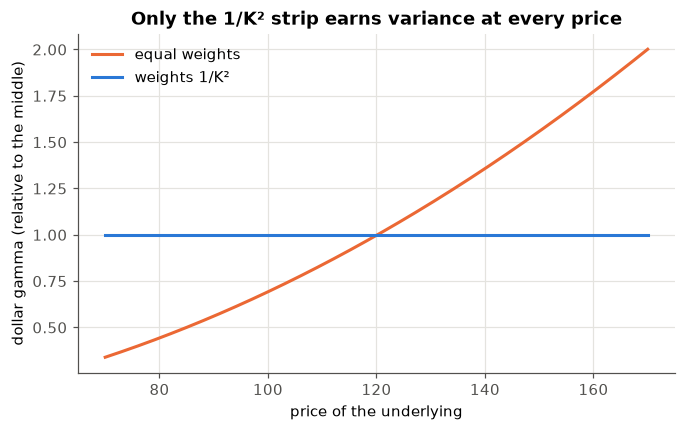

In [5]:
T, sigma, r = 30/365, 0.20, 0.0
strip = np.arange(40.0, 251.0, 1.0)
prices = np.linspace(70, 170, 300)


def dollar_gamma(F, weights):
    s = sigma*np.sqrt(T)
    d1 = (np.log(F/strip) + s*s/2)/s
    gamma = norm.pdf(d1)/(F*s)            # Black-76 gamma with respect to F (r = 0)
    return F**2*np.sum(weights*gamma)


fig, ax = plt.subplots()
for weights, colour, label in ((np.ones_like(strip), ORANGE, "equal weights"), (1/strip**2, BLUE, "weights 1/K²")):
    g = np.array([dollar_gamma(x, weights) for x in prices])
    ax.plot(prices, g/g[len(g)//2], color=colour, label=label)
ax.set(xlabel="price of the underlying", ylabel="dollar gamma (relative to the middle)",
       title="Only the 1/K² strip earns variance at every price")
ax.legend()
plt.show()

The figure shows the dollar gamma of two strips of 30-day options with strikes from 40 to 250, plotted against the
price of the underlying and scaled to 1 at a price of 120. With equal weights the dollar gamma grows with the price,
so the strip earns more variance when the price is high. With weights $1/K^2$ it is flat, so the strip earns the same
variance at every price level.

## 3. From an integral to a finite chain

Real chains have strikes $K_1<\dots<K_n$, often \$1 apart near the money, wider in the wings, over a limited range.
We must approximate

$$w = \int_0^\infty f(K)\,dK,\qquad f(K) = \frac{2e^{rT}Q(K)}{K^2}$$

from a finite set of points. How you do this matters more than it looks.

### 3.1 The integrand has a corner at the forward

Write the OTM price using both options. For $K<F$, parity gives $C = P + e^{-rT}(F-K)$, so
$\tfrac12(P + C) - \tfrac12e^{-rT}(F-K) = P = Q$, and the case $K>F$ works the same way. So for every $K$

$$Q(K) = \underbrace{\tfrac12\big(P(K)+C(K)\big)}_{\text{smooth half straddle}} - \underbrace{\tfrac12e^{-rT}|F-K|}_{\text{corner at }F}$$

Multiplying by $2e^{rT}/K^2$ splits the integrand into a smooth part and a known corner

$$f(K) = a(K) - b(K),\qquad a(K) = \frac{e^{rT}\big(P(K)+C(K)\big)}{K^2},\qquad b(K) = \frac{|F-K|}{K^2}$$

Integration rules (rectangle, trapezoid, Simpson) are accurate for smooth functions. $f$ is smooth everywhere except
at $K=F$. There the OTM price switches from a put (slope $+e^{-rT}\mathbb Q(S_T<K)$) to a call (slope
$-e^{-rT}\mathbb Q(S_T>K)$), so its slope drops by $e^{-rT}$ and the slope of $f$ drops by $2/F^2$. And the forward
almost never sits on a strike. It falls between two strikes, $K_0 < F < K_1$.

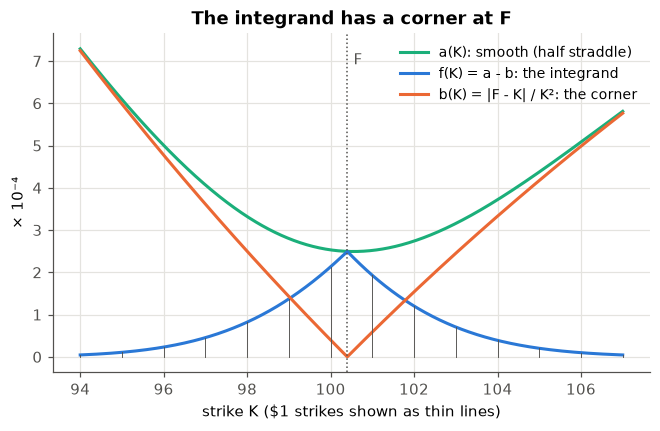

In [6]:
F, r, T, sigma = 100.4, 0.03, 9/365, 0.20
k = np.linspace(94, 107, 600)
P, C = black76(F, k, T, r, sigma, "put"), black76(F, k, T, r, sigma, "call")
f = 2*np.exp(r*T)*np.where(k < F, P, C)/k**2
a = np.exp(r*T)*(P + C)/k**2
b = np.abs(F - k)/k**2

fig, ax = plt.subplots()
ax.plot(k, 1e4*a, color=AQUA, label="a(K): smooth (half straddle)")
ax.plot(k, 1e4*f, color=BLUE, label="f(K) = a - b: the integrand")
ax.plot(k, 1e4*b, color=ORANGE, label="b(K) = |F - K| / K²: the corner")
ax.axvline(F, color=MUTED, lw=1, ls=":")
ax.text(F + 0.15, 1e4*a.max()*0.95, "F", color=MUTED)
for strike in range(94, 108):
    ax.plot([strike, strike], [0, 1e4*2*np.exp(r*T)*float(black76(F, strike, T, r, sigma, "put" if strike < F else "call"))/strike**2],
            color=MUTED, lw=0.6)
ax.set(xlabel="strike K ($1 strikes shown as thin lines)", ylabel="× 10⁻⁴", title="The integrand has a corner at F")
ax.legend(loc="upper right", fontsize=9)
plt.show()

The figure shows the three functions of the decomposition on a 9-day Black–Scholes chain with $F = 100.4$ and 20% vol,
in units of $10^{-4}$. The integrand $f$ (blue) peaks at the forward and has a corner there, because the
out-of-the-money price switches from a put to a call. The smooth part $a$ (green) has no corner, and the corner part
$b$ (orange) is exactly zero at $F$. The thin vertical lines mark the \$1 strikes where the integrand is actually
observed, and no strike falls on the corner.

### 3.2 The baseline, a rectangle (trapezoid) sum

Give each strike the width $D_i = (K_{i+1}-K_{i-1})/2$ (one-sided at the ends) and sum, with puts for $K_i\le K_0$
and calls for $K_i\ge K_1$

$$w_{\text{rect}} = 2e^{rT}\sum_i \frac{D_i}{K_i^2}Q(K_i)$$

On an even grid with spacing $h$ this is the trapezoid rule, because the end strikes are so far out of the money that
their prices are about zero. The Euler–Maclaurin formula gives its error for a smooth $g$ on $[\alpha,\beta]$

$$\int_\alpha^\beta g\,dK = T_h(g) - \frac{h^2}{12}\big[g'(\beta)-g'(\alpha)\big] + O(h^4)$$

The error depends only on the slopes at the two ends. Over a whole chain both end slopes are about zero (far OTM
prices are flat at zero), so for a smooth integrand the error would be tiny. The corner in the middle breaks this.

### 3.3 Fixing the corner, step by step

Apply the error formula to $a$ and $b$ separately. $a$ is smooth, so it contributes only end terms, which are about
zero. $b$ is smooth on $[K_{\min},K_0]$ and on $[K_1,K_{\max}]$, and on the gap $[K_0,K_1]$ it is known exactly. With
$h = K_1-K_0$, $b_0 = b(K_0)$ and $b_1 = b(K_1)$ this gives

$$\int f\,dK = T_h(f) + \underbrace{\frac{h}{2}(b_0+b_1) - \int_{K_0}^{K_1}\! b\,dK}_{\text{(i) area of the corner}} + \underbrace{\frac{h^2}{12}\big[b'(K_0) - b'(K_1)\big]}_{\text{(ii) slope jump}} + O(h^4)$$

Term (i) is the "bowtie". The trapezoid draws a straight line from $K_0$ to $K_1$ under a function that dips to a
corner at $F$, and we replace it by the exact area. Split at $F$ and use $\int (F-K)/K^2\,dK = -F/K - \ln K$ to get

$$\int_{K_0}^{F}\frac{F-K}{K^2}dK = \frac{F}{K_0} - 1 - \ln\frac{F}{K_0},\qquad \int_{F}^{K_1}\frac{K-F}{K^2}dK = \ln\frac{K_1}{F} + \frac{F}{K_1} - 1$$

$$\text{bowtie} \equiv -\int_{K_0}^{K_1} b\,dK = \ln\frac{F^2}{K_0K_1} - \frac{F}{K_0} - \frac{F}{K_1} + 2$$

Term (ii) is the slope jump. Differentiating $b$ on each side gives
$b'(K) = -\tfrac{1}{K^2} - \tfrac{2(F-K)}{K^3}$ for $K<F$ and $b'(K) = \tfrac{1}{K^2} - \tfrac{2(K-F)}{K^3}$ for $K>F$.
With $K_0, K_1\approx F$ this gives $b'(K_0) - b'(K_1) \approx -2/F^2$, so term (ii) $\approx -h^2/(6F^2)$. Since
$(F-K_0)+(K_1-F) = h$, we also have $b_0 + b_1 \approx h/F^2$, so term (ii) $\approx -\tfrac h6(b_0+b_1)$ and

$$\text{(i)} + \text{(ii)} \approx \Big(\frac h2 - \frac h6\Big)(b_0+b_1) + \text{bowtie} = \frac h3(b_0+b_1) + \text{bowtie}$$

The $1/3$ is Simpson's coefficient.

### 3.4 The full Simpson formula

Allowing uneven spacing next to the money, the formula (Heston, Jones, Khorram, Li and Mo, and Heston and Todorov) is

$$
\begin{aligned}
w = {} & 2e^{rT}\sum_i \frac{D_i}{K_i^2}Q_i && \text{rectangle sum}\\
&+ \frac{D}{3}\left(\frac{F-K_0}{K_0^2}+\frac{K_1-F}{K_1^2}\right) && \text{slope jump } \tfrac h3(b_0+b_1)\\
&+ \frac{e^{rT}}{3}\left(\frac{D-D_0}{K_0^2}P(K_0)+\frac{D-D_1}{K_1^2}C(K_1)\right) && \text{uneven-grid term (0 on an even grid)}\\
&+ \ln\frac{F^2}{K_0K_1} - \frac{F}{K_0} - \frac{F}{K_1} + 2 && \text{exact bowtie}
\end{aligned}
$$

with $K_0$ the highest put strike below $F$, $K_1$ the lowest call strike above, $D = K_1-K_0$, and $D_0, D_1$ the
rectangle widths of $K_0$ and $K_1$. For comparison, CBOE's VIX formula takes $K_0$ as the first strike at or below
$F$, uses the average of the put and the call there, and subtracts $(F/K_0-1)^2$

$$w_{\text{CBOE}} = 2e^{rT}\sum_i\frac{\Delta K_i}{K_i^2}Q(K_i) - \left(\frac{F}{K_0}-1\right)^2$$

In [7]:
def _check_inputs(k, q, F):
    k, q = np.asarray(k, dtype=float), np.asarray(q, dtype=float)
    if k.ndim != 1 or k.shape != q.shape or len(k) < 2 or np.any(np.diff(k) <= 0):
        raise ValueError("strikes must be a strictly increasing 1-d array matching the prices")
    if not (k[0] < F < k[-1]) or np.any(k == F):
        raise ValueError("F must lie strictly between two strikes")
    if not np.all(np.isfinite(q)) or np.any(q < 0):
        raise ValueError("prices must be finite and non-negative")
    return k, q


def bowtie(F, K0, K1):
    # minus the exact integral of |F - K| / K^2 over [K0, K1]
    return np.log(F**2/(K0*K1)) - F/K0 - F/K1 + 2


def rectangle_variance(k, q, F, disc):
    # k are the strikes used (sorted), q the OTM mids (puts below F, calls above), disc = e^{rT}
    k, q = _check_inputs(k, q, F)
    return float(np.sum(2*disc*np.gradient(k)/k**2*q))


def simpson_variance(k, q, F, disc, return_down=False):
    k, q = _check_inputs(k, q, F)
    d = np.gradient(k)                       # D_i = (K_{i+1} - K_{i-1}) / 2, one-sided at the ends
    terms = 2*disc*d/k**2*q
    i0 = int(np.searchsorted(k, F)) - 1      # highest strike below F
    i1 = i0 + 1
    K0, K1, P0, C1, D = k[i0], k[i1], q[i0], q[i1], k[i1] - k[i0]
    w = (terms.sum()
         + D/3*((F - K0)/K0**2 + (K1 - F)/K1**2)
         + disc/3*((D - d[i0])/K0**2*P0 + (D - d[i1])/K1**2*C1)
         + bowtie(F, K0, K1))
    return (float(w), float(terms[:i1].sum()/terms.sum())) if return_down else float(w)


def cboe_variance(k, put, call, F, disc):
    # CBOE's VIX method on a full chain, with put and call mids at every strike in k (NaN means no quote)
    k, put, call = (np.asarray(x, dtype=float) for x in (k, put, call))
    K0 = k[k <= F].max()
    q = np.where(k < K0, put, call)
    q = np.where(k == K0, (put + call)/2, q)
    use = np.isfinite(q)
    k, q = k[use], q[use]
    return float(np.sum(2*disc*np.gradient(k)/k**2*q) - (F/K0 - 1)**2)


def otm(F, strikes, puts, calls):
    strikes = np.asarray(strikes, dtype=float)
    keep = strikes != F
    return strikes[keep], np.where(strikes < F, puts, calls)[keep]


def strike_grid(F, h, lo, hi, offset=None):
    # even grid on [lo, hi], where offset in (0, 1) puts F that share of a spacing above the strike below it
    if offset is None:
        return np.round(np.arange(np.ceil(lo/h)*h, hi + 1e-9, h), 10)
    K0 = F - offset*h
    return np.round(np.arange(K0 - np.floor((K0 - lo)/h)*h, hi + 1e-9, h), 10)


for K0, K1, Fx in ((100.0, 101.0, 100.4), (95.0, 100.0, 96.2)):
    exact = quad(lambda x: abs(Fx - x)/x**2, K0, K1, points=[Fx])[0]
    check(abs(bowtie(Fx, K0, K1) + exact) < 1e-12, f"bowtie formula = exact integral on [{K0:.0f}, {K1:.0f}], F = {Fx}")

ok  bowtie formula = exact integral on [100, 101], F = 100.4
ok  bowtie formula = exact integral on [95, 100], F = 96.2


Does the slope-jump derivation really give the paper's $D/3$? The cell below implements the version with the exact
Euler–Maclaurin slope term next to the paper's formula. Both converge at fourth order, so the error falls about 16
times each time $h$ halves.

In [8]:
def em_variance(k, q, F, disc):
    # rectangle + trapezoid gap term + exact bowtie + exact Euler-Maclaurin slope-jump term
    i0 = int(np.searchsorted(k, F)) - 1
    K0, K1 = k[i0], k[i0 + 1]
    D = K1 - K0
    b0, b1 = (F - K0)/K0**2, (K1 - F)/K1**2
    slope0, slope1 = -1/K0**2 - 2*(F - K0)/K0**3, 1/K1**2 - 2*(K1 - F)/K1**3
    return rectangle_variance(k, q, F, disc) + D/2*(b0 + b1) + bowtie(F, K0, K1) + D**2/12*(slope0 - slope1)


F, r, T, sigma = 100.0, 0.03, 9/365, 0.20
disc, exact = np.exp(r*T), sigma**2*T
rows = []
for h in (5.0, 2.5, 1.0, 0.5):
    kk = strike_grid(F, h, 50, 150, offset=0.3)
    k_otm, q = otm(F, kk, black76(F, kk, T, r, sigma, "put"), black76(F, kk, T, r, sigma, "call"))
    rows.append(dict(h=h, exact_slope_term=em_variance(k_otm, q, F, disc)/exact - 1,
                     paper_D_over_3=simpson_variance(k_otm, q, F, disc)/exact - 1))
table = pd.DataFrame(rows).set_index("h")
display(table.style.format("{:+.6%}"))
ratio = table.paper_D_over_3.abs()
check(ratio.iloc[0]/ratio.iloc[1] > 12 and ratio.iloc[1]/ratio.iloc[2] > 30, "Simpson is fourth order (error ~ h^4)")

,exact_slope_term,paper_D_over_3
h,,
5.000000,-0.040239%,+0.110297%
2.500000,-0.001932%,+0.007714%
1.000000,-0.000050%,+0.000201%
0.500000,-0.000003%,+0.000013%


ok  Simpson is fourth order (error ~ h^4)


### 3.5 CBOE's bias of $h^2/(6F^2)$

CBOE's $-(F/K_0-1)^2$ handles the area of the corner (term (i)) but not the slope jump (term (ii)). So its error
should be the size of term (ii) with the opposite sign

$$w_{\text{CBOE}} - w \approx +\frac{h^2}{6F^2}\qquad\Longrightarrow\qquad \frac{w_{\text{CBOE}} - w}{w} \approx \frac16\left(\frac{h}{F\sigma\sqrt T}\right)^2 = \frac16\left(\frac{h}{\text{sd}}\right)^2$$

where $\text{sd} = F\sigma\sqrt T$ is the dollar standard deviation of the price at expiry. The bias is a fixed amount
of variance set by the strike spacing alone. A 30-day option carries a lot of variance, so the bias is small next to
it. A 1-day option carries very little, so the same bias is large. The cell measures both methods over 10 positions
of $F$ between two strikes.

,CBOE error,Simpson |error|,theory (h/sd)^2 / 6
days,,,
1,+15.3626%,+0.0018%,+15.2083%
2,+7.6813%,+0.0009%,+7.6042%
3,+5.1209%,+0.0006%,+5.0694%
5,+3.0725%,+0.0004%,+3.0417%
9,+1.7070%,+0.0002%,+1.6898%
15,+1.0242%,+0.0001%,+1.0139%
30,+0.5121%,+0.0001%,+0.5069%


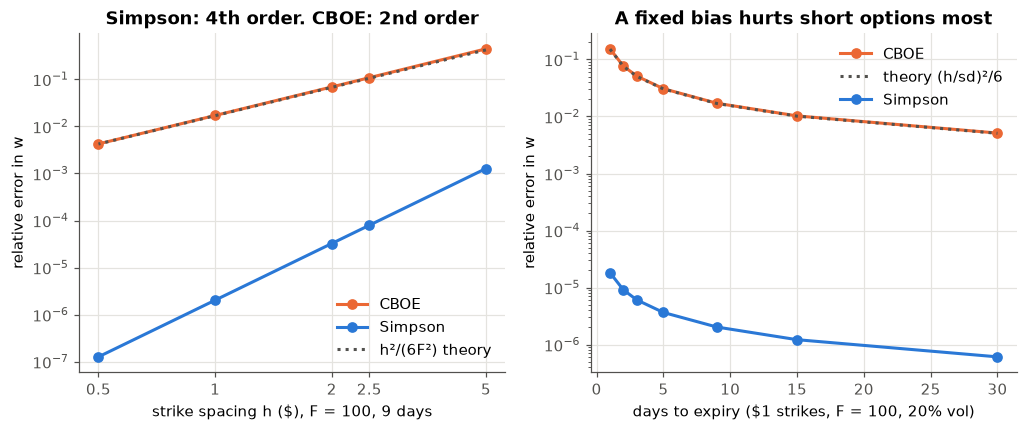

ok  CBOE's error matches (h/sd)^2/6 within 3% at every maturity


In [9]:
def bs_errors(T, h, offsets=np.linspace(0.05, 0.95, 10), F=100.0, r=0.03, sigma=0.20):
    sd = F*sigma*np.sqrt(T)
    disc, exact, ec, es = np.exp(r*T), sigma**2*T, [], []
    for o in offsets:
        kk = strike_grid(F, h, max(1.0, F - 8*sd), F + 8*sd, offset=o)
        p, c = black76(F, kk, T, r, sigma, "put"), black76(F, kk, T, r, sigma, "call")
        ec.append(cboe_variance(kk, p, c, F, disc)/exact - 1)
        es.append(abs(simpson_variance(*otm(F, kk, p, c), F, disc)/exact - 1))
    return np.mean(ec), np.mean(es), (h/sd)**2/6


days = [1, 2, 3, 5, 9, 15, 30]
res = pd.DataFrame([bs_errors(d/365, 1.0) for d in days], index=pd.Index(days, name="days"),
                   columns=["CBOE error", "Simpson |error|", "theory (h/sd)^2 / 6"])
display(res.style.format("{:+.4%}"))

spacings = [5.0, 2.5, 2.0, 1.0, 0.5]
conv = pd.DataFrame([bs_errors(9/365, h) for h in spacings], index=pd.Index(spacings, name="h"),
                    columns=["CBOE", "Simpson", "theory"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.loglog(spacings, conv.CBOE, "o-", color=ORANGE, label="CBOE")
a1.loglog(spacings, conv.Simpson, "o-", color=BLUE, label="Simpson")
a1.loglog(spacings, conv.theory, ":", color=MUTED, label="h²/(6F²) theory")
a1.set_xticks(spacings, [f"{h:g}" for h in spacings])
a1.minorticks_off()
a1.set(xlabel="strike spacing h ($), F = 100, 9 days", ylabel="relative error in w",
       title="Simpson: 4th order. CBOE: 2nd order")
a1.legend()
a2.semilogy(days, res.iloc[:, 0], "o-", color=ORANGE, label="CBOE")
a2.semilogy(days, res.iloc[:, 2], ":", color=MUTED, label="theory (h/sd)²/6")
a2.semilogy(days, res.iloc[:, 1], "o-", color=BLUE, label="Simpson")
a2.set(xlabel="days to expiry ($1 strikes, F = 100, 20% vol)", ylabel="relative error in w",
       title="A fixed bias hurts short options most")
a2.legend()
plt.show()
check(np.allclose(res.iloc[:, 0], res.iloc[:, 2], rtol=0.03), "CBOE's error matches (h/sd)^2/6 within 3% at every maturity")

The left panel shows the relative error in total variance against the strike spacing for a 9-day Black–Scholes chain,
on log scales. CBOE's error (orange) falls with the square of the spacing and lies on the dotted $h^2/(6F^2)$ line,
while Simpson's error (blue) falls with the fourth power and is about four orders of magnitude smaller at \$1 strikes.
The right panel holds the spacing at \$1 and varies the maturity from 1 to 30 days. CBOE's error grows from 0.5% at 30
days to 15% at 1 day and follows the theory line, while Simpson's error stays below 0.002%.

For real products the bias looks like this. For SPY (about \$600, \$1 strikes, 15% vol) it is about 0.5% of a 1-day
variance and 0.1% of a 5-day variance. For IWM (about \$220, \$1 strikes, 20% vol) it is about 2.2% and 0.4%. Simpson
matters for 1–2 day horizons, coarse strike grids and low-priced underlyings. At a 5-session horizon the bias is
small, which matters for reading the results in Section 9.

### 3.6 A trap in changes of strike spacing

The fourth-order accuracy needs an even grid near the money. If the spacing changes from $h_a$ to $h_b$ at a
strike $x$, the Euler–Maclaurin end terms of the two pieces no longer cancel, and they leave the error

$$-\frac{h_a^2 - h_b^2}{12}\,f'(x)$$

This is a second-order error, and it is large where $f$ is steep, which is near the money. Many real chains have
\$0.5 strikes near the money and \$1 further out. The cell below shows what that does.

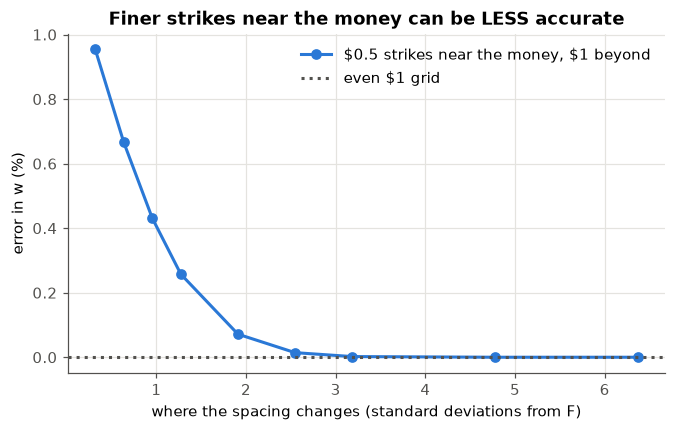

$0.5 strikes within $1 of the money: +0.955%;  even $1 grid: +0.00020%
ok  a spacing change near F costs accuracy; beyond ~4 sd it is harmless


In [10]:
F, r, T, sigma = 100.3, 0.03, 9/365, 0.20
disc, exact, sd = np.exp(r*T), sigma**2*T, 100*sigma*np.sqrt(9/365)


def error_on(kk):
    p, c = black76(F, kk, T, r, sigma, "put"), black76(F, kk, T, r, sigma, "call")
    return simpson_variance(*otm(F, kk, p, c), F, disc)/exact - 1


bands = np.array([1, 2, 3, 4, 6, 8, 10, 15, 20])
uneven = [error_on(np.union1d(np.arange(100 - b, 100 + b + 1e-9, 0.5), np.arange(40.0, 161.0, 1.0))) for b in bands]
even = error_on(np.arange(40.0, 161.0, 1.0))

fig, ax = plt.subplots()
ax.plot(bands/sd, 100*np.array(uneven), "o-", color=BLUE, label=r"\$0.5 strikes near the money, \$1 beyond")
ax.axhline(100*even, color=MUTED, ls=":", label=r"even \$1 grid")
ax.set(xlabel="where the spacing changes (standard deviations from F)", ylabel="error in w (%)",
       title="Finer strikes near the money can be LESS accurate")
ax.legend()
plt.show()
print(f"$0.5 strikes within $1 of the money: {uneven[0]:+.3%};  even $1 grid: {even:+.5%}")
check(abs(uneven[0]) > 100*abs(even) and abs(uneven[-2]) < 1e-5, "a spacing change near F costs accuracy; beyond ~4 sd it is harmless")

The figure shows Simpson's error on a 9-day Black–Scholes chain with \$0.5 strikes inside a band around the money and
\$1 strikes outside it, plotted against the distance from $F$ where the spacing changes, in standard deviations of the
price at expiry. A change within 1 sd of $F$ adds an error of 0.4% to 1%, thousands of times the 0.0002% error of an
even \$1 grid (dotted line). Beyond about 3 sd the change is harmless.

Finer strikes near the money make the estimate worse unless the spacing change sits more than about 3 sd away. The
fix is to apply the end correction above at every strike where the spacing changes.

## 4. A worked example

The example uses a Black–Scholes chain with $F = 100.4$, $r = 3\%$, 9 days, $\sigma = 20\%$ and strikes 85, 86, …, 115.
The true answer is $w = \sigma^2T$. The cell follows the numbers through each step of the formula.

In [11]:
F, r, days, sigma = 100.4, 0.03, 9, 0.20
T = days/365
disc, exact = np.exp(r*T), sigma**2*T
chain_k = np.arange(85.0, 116.0)
P, C = black76(F, chain_k, T, r, sigma, "put"), black76(F, chain_k, T, r, sigma, "call")

print(f"Step 1  T = {T:.6f} years;  e^(rT) = {disc:.5f};  true w = sigma^2 T = {exact:.8f}")
print(f"        parity at K = 100: C - P = {C[15] - P[15]:.5f}  ->  F = 100 + e^(rT)(C - P) = {100 + disc*(C[15] - P[15]):.4f}")
k, q = otm(F, chain_k, P, C)
K0, K1 = k[k < F].max(), k[k > F].min()
print(f"Step 2  K0 = {K0:.0f} (highest put strike below F), K1 = {K1:.0f} (lowest call strike above), D = {K1 - K0:.0f}")
print("Step 3  rectangle terms 2 e^(rT) D_i Q_i / K_i^2 near the money:")
terms = 2*disc*np.gradient(k)/k**2*q
for K, Qk, t in zip(k, q, terms):
    if 97 <= K <= 104:
        print(f"          K = {K:4.0f} {'put ' if K < F else 'call'}  Q = {Qk:.5f}  term = {t:.4e}")
rect = rectangle_variance(k, q, F, disc)
print(f"        sum over all {len(k)} strikes = {rect:.8f}   (the 85 put adds only {terms[0]:.0e})")
slope = (K1 - K0)/3*((F - K0)/K0**2 + (K1 - F)/K1**2)
bow = bowtie(F, K0, K1)
print(f"Step 4  slope-jump term = {slope:.4e};  uneven-grid term = 0 (even grid);  bowtie = {bow:.4e}")
w, down = simpson_variance(k, q, F, disc, return_down=True)
print(f"Step 5  w = {rect:.8f} + {slope:.8f} + 0 + ({bow:.8f}) = {w:.8f}")
print(f"        relative error {w/exact - 1:.1e};  annualised vol sqrt(w/T) = {100*np.sqrt(w/T):.5f}%")
print(f"Step 6  downside share (put part of the rectangle sum) = {down:.2f}")
trap_bow = rect + (K1 - K0)/2*((F - K0)/K0**2 + (K1 - F)/K1**2) + bow
print()
print(f"Compare: rectangle only {rect/exact - 1:+.2%} | rectangle + bowtie, slope jump ignored {trap_bow/exact - 1:+.2%} "
      f"(h^2/6F^2 = {1/(6*F**2)/exact:+.2%}) | Simpson {w/exact - 1:+.4%}")
check(abs(w/exact - 1) < 1e-5, "the worked example recovers sigma^2 T")

Step 1  T = 0.024658 years;  e^(rT) = 1.00074;  true w = sigma^2 T = 0.00098630
        parity at K = 100: C - P = 0.39970  ->  F = 100 + e^(rT)(C - P) = 100.4000
Step 2  K0 = 100 (highest put strike below F), K1 = 101 (lowest call strike above), D = 1
Step 3  rectangle terms 2 e^(rT) D_i Q_i / K_i^2 near the money:
          K =   97 put   Q = 0.21377  term = 4.5472e-05
          K =   98 put   Q = 0.39408  term = 8.2127e-05
          K =   99 put   Q = 0.67140  term = 1.3711e-04
          K =  100 put   Q = 1.06469  term = 2.1310e-04
          K =  101 call  Q = 0.98352  term = 1.9297e-04
          K =  102 call  Q = 0.62476  term = 1.2019e-04
          K =  103 call  Q = 0.37416  term = 7.0588e-05
          K =  104 call  Q = 0.21074  term = 3.8996e-05
        sum over all 31 strikes = 0.00097906   (the 85 put adds only 8e-12)
Step 4  slope-jump term = 3.2939e-05;  uneven-grid term = 0 (even grid);  bowtie = -2.5694e-05
Step 5  w = 0.00097906 + 0.00003294 + 0 + (-0.00002569) = 0.000

## 5. Real chains, cleaning and choosing quotes

The math assumes clean prices at every strike. Real end-of-day data has stale quotes, zero bids, crossed markets
and gaps. A chain slice below is one (date, expiry) with columns `strike, type, bid, ask`.

- A quote is valid if $0\le\text{bid}\le\text{ask}$ and $0<\text{ask}\le 2\,\text{bid}+0.5$, which drops crossed and
  absurdly wide quotes. To enter the sum a quote also needs $\text{bid}>0$. A zero bid means nobody will buy the
  option, so its true price is unknown. The price used is the mid, and the vendor's implied vols and greeks are not
  used.
- The forward comes from parity, $F = K + e^{rT}\big(C(K)-P(K)\big)$, at the strike where $|C-P|$ is smallest (the
  most liquid quotes). This absorbs dividends and borrow costs, which you can't observe cleanly. The rate is the
  3-month T-bill (FRED series DTB3) and $T$ is the number of calendar days to the last trading day divided by 365.
- CBOE's wing rule walks outward from $F$, and after the first usable quote it stops as soon as two listed strikes in
  a row have none. Far wings are full of stale quotes, and a strike with no bid means that market has stopped.
- If more than 10% of the quotes within ±10% of $F$ are invalid, the expiry is dropped for that day. Clean chains
  have none, and on real chains this drops 0.4–0.8% of expiry-days.

In [12]:
def valid(chain):
    bid, ask = chain.bid, chain.ask
    return bid.ge(0) & ask.ge(bid) & ask.gt(0) & ask.le(2*bid + 0.5)


def mids(chain):
    # mids of usable quotes (valid and bid > 0) as (puts, calls), each a Series indexed by strike
    u = chain.loc[valid(chain) & chain.bid.gt(0)]
    mid = (u.bid + u.ask)/2
    return tuple(pd.Series(mid[u.type.eq(side)].to_numpy(), index=u.strike[u.type.eq(side)].to_numpy(), dtype=float)
                 .groupby(level=0).mean() for side in ("put", "call"))


def parity_forward(chain, disc):
    puts, calls = mids(chain)
    both = puts.index.intersection(calls.index)
    if len(both) == 0:
        return np.nan
    gap = calls[both] - puts[both]
    k_atm = gap.abs().idxmin()
    return float(k_atm + disc*gap[k_atm])


def wings(chain, F):
    # strikes and OTM mids that enter the sum (CBOE's rule), plus the number of put and call strikes
    puts, calls = mids(chain)
    strikes = np.sort(chain.strike.unique())
    sides = []
    for ks, m in ((strikes[strikes < F][::-1], puts), (strikes[strikes > F], calls)):
        chosen, misses = {}, 0
        for x in ks:                          # outward from the money
            if x in m.index:
                chosen[x], misses = m[x], 0
            elif chosen:
                misses += 1
                if misses >= 2:
                    break
        sides.append(pd.Series(chosen, dtype=float).sort_index())
    k = np.concatenate([sides[0].index.to_numpy(float), sides[1].index.to_numpy(float)])
    return k, np.concatenate([sides[0].to_numpy(), sides[1].to_numpy()]), len(sides[0]), len(sides[1])


def corrupted(chain, F, near=0.10, max_invalid=0.10):
    close = chain.loc[(chain.strike/F - 1).abs().le(near)]
    return len(close) == 0 or (1 - valid(close).mean()) > max_invalid


def synthetic_slice(F, strikes, T, sigma=0.20, r=0.03, spread=0.02):
    rows = []
    for kind in ("put", "call"):
        for x, px in zip(strikes, black76(F, strikes, T, r, sigma, kind)):
            rows.append(dict(strike=x, type=kind, bid=max(px - spread/2, 0.0), ask=px + spread/2))
    return pd.DataFrame(rows)


T = 20/365
sl = synthetic_slice(98.37, np.arange(80.0, 121.0), T, spread=0.0)          # forward below spot, as with dividends
check(abs(parity_forward(sl, np.exp(0.03*T)) - 98.37) < 1e-9, "parity recovers the forward from quotes alone")

sl = synthetic_slice(100.4, np.arange(80.0, 121.0), 9/365)
sl.loc[sl.strike.isin([95.0, 94.0]) & sl.type.eq("put"), "bid"] = 0.0      # two missing puts in a row
sl.loc[sl.strike.eq(104.0) & sl.type.eq("call"), "bid"] = 0.0              # one missing call
k, q, n_put, n_call = wings(sl, 100.4)
check(k.min() == 96.0 and n_put == 5, "two missing strikes in a row end a wing")
check(104.0 not in k and k.max() > 105.0, "one missing strike does not")

sl = synthetic_slice(100.4, np.arange(80.0, 121.0), 9/365)
check(not corrupted(sl, 100.4), "a clean slice passes the corruption filter")
bad = sl.index[(sl.strike/100.4 - 1).abs().le(0.1)][::5]
sl.loc[bad, "ask"] = sl.loc[bad, "bid"] - 0.01                               # crossed quotes near the money
check(corrupted(sl, 100.4), "a slice with 20% crossed quotes near F is dropped")

ok  parity recovers the forward from quotes alone
ok  two missing strikes in a row end a wing
ok  one missing strike does not
ok  a clean slice passes the corruption filter
ok  a slice with 20% crossed quotes near F is dropped


## 6. From expiries to a fixed horizon

Options expire on fixed dates, but we want a constant horizon, such as "the next 5 trading sessions".

#### Interpolate total variance, not volatility

Variance adds over time. The variance to $t_2$ is the variance to $t_1$ plus the forward variance between them. So
$w(t)$ must increase with $t$, and linear interpolation in $w$ means a constant forward variance between two expiries

$$w(H) = w(t_i) + \frac{H - t_i}{t_j - t_i}\big(w(t_j) - w(t_i)\big),\qquad t_i < H \le t_j$$

With no expiry before $H$, scale the first one after it, $w(H) = w(t_j)\,H/t_j$. The output is the mean implied
variance per session, $\text{iv}_H = w(H)/H$.

#### Count trading sessions, not calendar days

$t$ is the number of exchange sessions after today up to and including the last trading day, so a Monday close to a
Friday expiry is 4 sessions. A weekend is one overnight gap, not three days of trading, and realised variance over a
weekend is far less than three normal days (French and Roll 1986). If the target is "variance over the next 5
sessions", use the clock the target uses.

#### Calendar convention, for validation only

To compare with CBOE, we also interpolate in calendar days and report $\text{vol}_d = 100\sqrt{w(d)\cdot365/d}$.

In [13]:
def last_trading_day(expiration):
    # Saturday-dated expiries (US monthlies before 2015) last trade on the Friday before
    e = pd.to_datetime(pd.Series(expiration)).reset_index(drop=True)
    return e - pd.to_timedelta(e.dt.weekday.eq(5).astype(int), unit="D")


def sessions_between(date, last_trade, sessions):
    # number of sessions in (date, last_trade]
    s = np.sort(pd.DatetimeIndex(sessions).to_numpy())
    return (np.searchsorted(s, pd.DatetimeIndex(last_trade).to_numpy(), side="right")
            - np.searchsorted(s, pd.DatetimeIndex(date).to_numpy(), side="right"))


def interpolate(t, w, target):
    t, w = np.asarray(t, dtype=float), np.asarray(w, dtype=float)
    ok = np.isfinite(w)
    t, w = t[ok], w[ok]
    after = t >= target
    if not after.any():
        return np.nan
    j = np.flatnonzero(after)[np.argmin(t[after])]
    if t[j] == target or not (~after).any():
        return w[j]*target/t[j]
    i = np.flatnonzero(~after)[np.argmax(t[~after])]
    return w[i] + (target - t[i])/(t[j] - t[i])*(w[j] - w[i])


sessions = pd.bdate_range("2014-01-01", "2014-03-31")
check(last_trading_day(["2014-01-18"]).iloc[0] == pd.Timestamp("2014-01-17"), "a Saturday expiry trades last on Friday")
check(sessions_between(["2014-01-13"], ["2014-01-17"], sessions)[0] == 4, "Monday close -> Friday expiry = 4 sessions")
check(sessions_between(["2014-01-17"], ["2014-01-20"], sessions)[0] == 1, "a weekend counts as one session")
check(abs(interpolate([4, 9], [0.4, 0.9], 5) - 0.5) < 1e-15, "a flat term structure is reproduced exactly")

# Why not interpolate vol? 1-day vol 10%, 10-day vol 30% (annualised-by-days units).
w1, w10 = 0.10**2*1, 0.30**2*10
vol_interp = 0.10 + (5.5 - 1)/9*(0.30 - 0.10)
var_interp = np.sqrt(interpolate([1, 10], [w1, w10], 5.5)/5.5)
print(f"vol at 5.5 days: interpolating vol gives {vol_interp:.1%}, interpolating total variance gives {var_interp:.1%}")

ok  a Saturday expiry trades last on Friday
ok  Monday close -> Friday expiry = 4 sessions
ok  a weekend counts as one session
ok  a flat term structure is reproduced exactly
vol at 5.5 days: interpolating vol gives 20.0%, interpolating total variance gives 28.8%


## 7. The synthetic test lab

On real data you never know the true answer, but on synthetic chains you do. We use three models, all priced from
their characteristic function $\varphi_T(u) = \mathbb E^{\mathbb Q}[e^{iu\ln(S_T/F)}]$ with the Lewis (2001) formula,
where $k = \ln(F/K)$

$$C(K) = e^{-rT}\left[F - \frac{\sqrt{FK}}{\pi}\int_0^\infty \frac{\operatorname{Re}\big[e^{iuk}\,\varphi_T(u - \tfrac i2)\big]}{u^2+\tfrac14}\,du\right]$$

#### Black–Scholes

Here $\varphi_T(u) = e^{-\frac12\sigma^2T(iu+u^2)}$ and $w = \sigma^2T$.

#### Heston

Heston has random volatility with leverage, $dS/S = \dots + \sqrt{v}\,dW^S$ and
$dv = \kappa(\theta - v)\,dt + \xi\sqrt{v}\,dW^v$ with $d\langle W^S,W^v\rangle = \rho\,dt$. Taking expectations of the
variance equation gives $\tfrac{d}{dt}\mathbb E[v_t] = \kappa(\theta - \mathbb E[v_t])$, so
$\mathbb E[v_t] = \theta + (v_0-\theta)e^{-\kappa t}$ and

$$w = \int_0^T\mathbb E[v_t]\,dt = \theta T + (v_0-\theta)\frac{1-e^{-\kappa T}}{\kappa}$$

We use its characteristic function in the stable "little trap" form (Albrecher et al. 2007). With
$\beta = \kappa - i\rho\xi u$, $d = \sqrt{\beta^2 + \xi^2(iu + u^2)}$ and $g = (\beta - d)/(\beta + d)$ it is

$$\varphi_T(u) = \exp\!\Big(\frac{\kappa\theta}{\xi^2}\Big[(\beta-d)T - 2\ln\frac{1-ge^{-dT}}{1-g}\Big] + \frac{\beta-d}{\xi^2}\,\frac{1-e^{-dT}}{1-ge^{-dT}}\,v_0\Big)$$

#### Merton jumps

Merton adds log-jumps $J\sim N(\mu_J,\delta^2)$ at rate $\lambda$ to a diffusion with volatility $\sigma$. Section 7.4
derives what the index measures then.

In [14]:
@dataclass(frozen=True)
class BlackScholes:
    sigma: float

    def phi(self, u, T):
        return np.exp(-0.5*self.sigma**2*T*(1j*u + u*u))

    def log_contract(self, T):           # -2 E[ln S_T/F], what the index measures
        return self.sigma**2*T

    expected_qv = log_contract           # E[quadratic variation], what a variance swap pays


@dataclass(frozen=True)
class Heston:
    v0: float
    kappa: float
    theta: float
    xi: float
    rho: float

    def phi(self, u, T):
        b = self.kappa - 1j*self.rho*self.xi*u
        d = np.sqrt(b*b + self.xi**2*(1j*u + u*u))
        g = (b - d)/(b + d)
        e = np.exp(-d*T)
        A = self.kappa*self.theta/self.xi**2*((b - d)*T - 2*np.log((1 - g*e)/(1 - g)))
        B = (b - d)/self.xi**2*(1 - e)/(1 - g*e)
        return np.exp(A + B*self.v0)

    def log_contract(self, T):
        return self.theta*T + (self.v0 - self.theta)*(1 - np.exp(-self.kappa*T))/self.kappa

    expected_qv = log_contract


@dataclass(frozen=True)
class Merton:
    sigma: float
    lam: float
    mu_j: float
    delta: float

    @property
    def kappa(self):                     # E[e^J - 1]
        return np.exp(self.mu_j + self.delta**2/2) - 1

    def phi(self, u, T):
        jump = np.exp(1j*u*self.mu_j - 0.5*self.delta**2*u*u) - 1
        return np.exp(T*(-0.5*self.sigma**2*(1j*u + u*u) - 1j*u*self.lam*self.kappa + self.lam*jump))

    def log_contract(self, T):           # sigma^2 T + 2 lam T E[e^J - 1 - J]
        return self.sigma**2*T + 2*self.lam*T*(self.kappa - self.mu_j)

    def expected_qv(self, T):            # sigma^2 T + lam T E[J^2]
        return self.sigma**2*T + self.lam*T*(self.mu_j**2 + self.delta**2)


def lewis_call(model, F, K, T, r):
    k = np.log(F/K)
    integrand = lambda u: (np.exp(1j*u*k)*model.phi(u - 0.5j, T)).real/(u*u + 0.25)
    return np.exp(-r*T)*(F - np.sqrt(F*K)/np.pi*quad(integrand, 0, np.inf, limit=1000, epsabs=1e-13, epsrel=1e-11)[0])


def model_chain(model, F, strikes, T, r):
    calls = np.array([lewis_call(model, F, x, T, r) for x in strikes])
    return np.maximum(calls - np.exp(-r*T)*(F - strikes), 0.0), np.maximum(calls, 0.0)


for days in (1, 9, 182):
    for x in (80.0, 100.0, 125.0):
        assert abs(lewis_call(BlackScholes(0.2), 100.0, x, days/365, 0.03)
                   - float(black76(100.0, x, days/365, 0.03, 0.2, "call"))) < 1e-10
check(True, "Lewis pricer with the Black-Scholes characteristic function = Black-76 to 1e-10 (1, 9, 182 days)")
for m in (BlackScholes(0.2), Heston(0.04, 2.0, 0.06, 0.5, -0.7), Merton(0.15, 1.0, -0.05, 0.05)):
    assert abs(m.phi(-1j, 0.5) - 1) < 1e-12
check(True, "every model is a martingale: E[S_T/F] = phi(-i) = 1")

H = Heston(v0=0.04, kappa=2.0, theta=0.06, xi=0.5, rho=-0.7)
rng, n, steps, T = np.random.default_rng(0), 20000, 200, 0.25
v, acc = np.full(n, H.v0), np.zeros(n)
for _ in range(steps):                   # full-truncation Euler
    vp = np.maximum(v, 0)
    acc += vp*T/steps
    v = v + H.kappa*(H.theta - vp)*T/steps + H.xi*np.sqrt(vp*T/steps)*rng.standard_normal(n)
print(f"Heston E[integrated variance], 3 months: closed form {H.log_contract(T):.6f}, Monte Carlo {acc.mean():.6f} "
      f"(± {acc.std()/np.sqrt(n):.6f})")
check(abs(acc.mean() - H.log_contract(T)) < 3*acc.std()/np.sqrt(n) + 2e-5, "closed-form Heston variance matches Monte Carlo")

ok  Lewis pricer with the Black-Scholes characteristic function = Black-76 to 1e-10 (1, 9, 182 days)
ok  every model is a martingale: E[S_T/F] = phi(-i) = 1


Heston E[integrated variance], 3 months: closed form 0.011065, Monte Carlo 0.011064 (± 0.000044)
ok  closed-form Heston variance matches Monte Carlo


### 7.1 Convergence under stochastic volatility (Heston)

This is the same comparison as Section 3.5, but on Heston chains with strong negative skew, where the smile is far
from flat.

In [15]:
F, r, T = 100.0, 0.03, 9/365
disc, exact = np.exp(r*T), H.log_contract(T)
rows = []
for h in (5.0, 2.5, 1.0, 0.5):
    kk = strike_grid(F, h, 60, 140, offset=0.3)
    p, c = model_chain(H, F, kk, T, r)
    rows.append(dict(h=h, CBOE=cboe_variance(kk, p, c, F, disc)/exact - 1,
                     Simpson=simpson_variance(*otm(F, kk, p, c), F, disc)/exact - 1))
heston_conv = pd.DataFrame(rows).set_index("h")
display(heston_conv.style.format("{:+.5%}"))
check(abs(heston_conv.Simpson.loc[1.0]) < 1e-5, "Simpson recovers Heston's expected variance to 1e-5 with $1 strikes")

,CBOE,Simpson
h,,
5.000000,+44.07945%,+0.13498%
2.500000,+10.72249%,+0.00762%
1.000000,+1.68787%,+0.00020%
0.500000,+0.41967%,+0.00001%


ok  Simpson recovers Heston's expected variance to 1e-5 with $1 strikes


### 7.2 Truncation, only quoted strikes count

The integrand is positive, so cutting the strip short always biases $w$ down. With negative skew ($\rho<0$) more
variance sits in the far put wing, so truncation costs more.

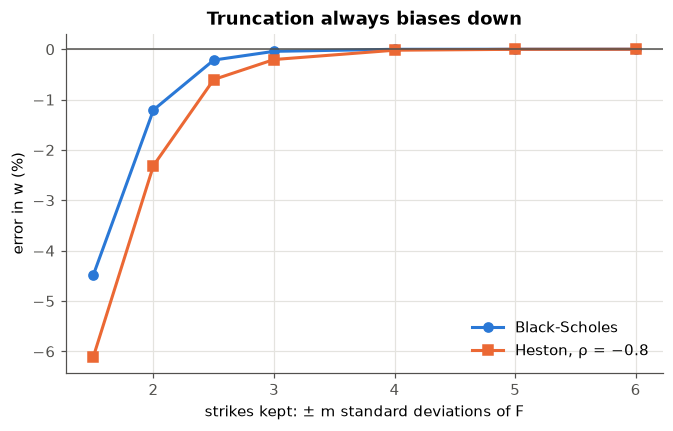

,Black-Scholes,"Heston, rho = -0.8"
strikes kept: ± sd,,
1.500000,-4.4902%,-6.1165%
2.000000,-1.2045%,-2.3093%
2.500000,-0.2150%,-0.6013%
3.000000,-0.0416%,-0.2041%
4.000000,-0.0011%,-0.0195%
5.000000,+0.0000%,-0.0014%
6.000000,+0.0000%,-0.0000%


ok  truncation only ever lowers w (by over 4% at ±1.5 sd)


In [16]:
F, r, T = 100.3, 0.03, 9/365
disc, sd = np.exp(r*T), 100*0.2*np.sqrt(T)
H_skew = Heston(v0=0.04, kappa=2.0, theta=0.04, xi=0.6, rho=-0.8)
full = strike_grid(F, 0.5, 40, 160)
bs_p, bs_c = black76(F, full, T, r, 0.2, "put"), black76(F, full, T, r, 0.2, "call")
he_p, he_c = model_chain(H_skew, F, full, T, r)

widths = np.array([1.5, 2, 2.5, 3, 4, 5, 6])
trunc = []
for m in widths:
    keep = np.abs(full - F) <= m*sd
    trunc.append((simpson_variance(*otm(F, full[keep], bs_p[keep], bs_c[keep]), F, disc)/(0.04*T) - 1,
                  simpson_variance(*otm(F, full[keep], he_p[keep], he_c[keep]), F, disc)/H_skew.log_contract(T) - 1))
trunc = pd.DataFrame(trunc, index=pd.Index(widths, name="strikes kept: ± sd"), columns=["Black-Scholes", "Heston, rho = -0.8"])

fig, ax = plt.subplots()
ax.plot(widths, 100*trunc.iloc[:, 0], "o-", color=BLUE, label="Black-Scholes")
ax.plot(widths, 100*trunc.iloc[:, 1], "s-", color=ORANGE, label="Heston, ρ = −0.8")
ax.axhline(0, color=MUTED, lw=1)
ax.set(xlabel="strikes kept: ± m standard deviations of F", ylabel="error in w (%)", title="Truncation always biases down")
ax.legend()
plt.show()
display(trunc.style.format("{:+.4%}"))
check((trunc.to_numpy() <= trunc.iloc[-1].to_numpy() + 1e-12).all() and (trunc.iloc[0] < -0.04).all(),
      "truncation only ever lowers w (by over 4% at ±1.5 sd)")

The figure shows the error in total variance when only strikes within ±m standard deviations of the forward are
kept, for a 9-day Black–Scholes chain and a Heston chain with strong negative skew. Every error is negative. Keeping
±2 sd loses 1.2% under Black–Scholes and 2.3% under Heston, and beyond 4 sd the loss is negligible in both. The Heston
chain loses more because its fat left tail puts more variance in the far put strikes.

### 7.3 Realistic quotes, through the full pipeline

Each synthetic chain gets bid and ask quotes on a \$0.01 tick around a noisy price, with 5% of bids missing at random.
It then goes through the full pipeline of quote rules, parity forward, wing rule and Simpson. For an option with true
price $p$ the half-spread is $s = \max(0.01, 0.04\,p)$, the centre is $p + U(-s/2, s/2)$, the bid is the centre minus
$s$ rounded down to the cent, and the ask is the centre plus $s$ rounded up to the cent.

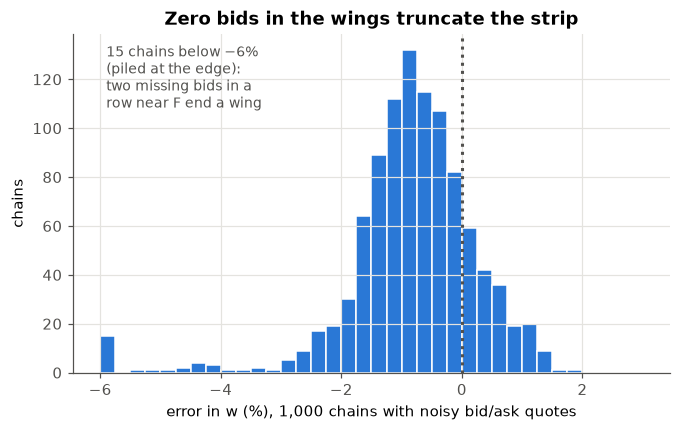

median error -0.77%;  5-95% range [-2.40%, +0.74%]
the strip reaches a median 1.7 sd below F and 2.1 sd above: far OTM bids round to zero


In [17]:
F, r, T, sigma, N = 100.4, 0.03, 9/365, 0.20, 1000
disc = np.exp(r*T)
strikes = np.arange(60.0, 141.0)
true = {kind: black76(F, strikes, T, r, sigma, kind) for kind in ("put", "call")}
rng = np.random.default_rng(7)
errs, reach = [], []
for _ in range(N):
    parts = []
    for kind in ("put", "call"):
        p = true[kind]
        s = np.maximum(0.01, 0.04*p)
        centre = p + rng.uniform(-0.5, 0.5, len(p))*s
        bid = np.maximum(np.floor((centre - s)*100)/100, 0)
        ask = np.ceil((centre + s)*100)/100
        bid[rng.random(len(p)) < 0.05] = 0.0
        parts.append(pd.DataFrame(dict(strike=strikes, type=kind, bid=bid, ask=ask)))
    sl = pd.concat(parts, ignore_index=True)
    f_hat = parity_forward(sl, disc)
    k, q, _, _ = wings(sl, f_hat)
    errs.append(simpson_variance(k, q, f_hat, disc)/(sigma**2*T) - 1)
    reach.append(((F - k.min())/(F*sigma*np.sqrt(T)), (k.max() - F)/(F*sigma*np.sqrt(T))))
errs, reach = np.array(errs), np.median(reach, axis=0)

fig, ax = plt.subplots()
ax.hist(np.clip(100*errs, -6, None), bins=np.arange(-6, 3.01, 0.25), color=BLUE, edgecolor="white")
ax.axvline(0, color=MUTED, ls=":")
ax.text(-5.9, 0.97*ax.get_ylim()[1], f"{(100*errs < -6).sum()} chains below −6%\n(piled at the edge):\ntwo missing bids in a\nrow near F end a wing",
        fontsize=9, color=MUTED, va="top")
ax.set(xlabel="error in w (%), 1,000 chains with noisy bid/ask quotes", ylabel="chains",
       title="Zero bids in the wings truncate the strip")
plt.show()
lo, med, hi = np.percentile(errs, [5, 50, 95])
print(f"median error {med:+.2%};  5-95% range [{lo:+.2%}, {hi:+.2%}]")
print(f"the strip reaches a median {reach[0]:.1f} sd below F and {reach[1]:.1f} sd above: far OTM bids round to zero")

The histogram shows the error in total variance for 1,000 synthetic 9-day chains with noisy quotes on a \$0.01 tick,
run through the full pipeline. The errors centre on −0.8% rather than zero, with 90% of chains between −2.4% and
+0.7%. The bar at −6% collects the 15 chains with larger losses, where two missing bids close to the forward ended a
wing early.

The integration rule is no longer the issue. On a \$0.01 tick, far out-of-the-money bids round to zero, the wing rule
stops there, and the truncated strip biases $w$ down by about 0.8% (median). Rare bad draws, where two missing bids in
a row close to $F$ end a wing early, cost more than 6%.

### 7.4 Jumps, the one assumption that fails

With jumps $J$ at rate $\lambda$, we redo Section 2.3 with the jump compensator. The log contract now prices

$$-2\,\mathbb E^{\mathbb Q}\Big[\ln\frac{S_T}{F}\Big] = \mathbb E\Big[\int_0^T\sigma_t^2dt\Big] + 2\lambda T\,\mathbb E\big[e^J - 1 - J\big]$$

while the expected quadratic variation (what a variance swap pays) is $\mathbb E[\int\sigma^2dt] + \lambda T\,\mathbb E[J^2]$.
The difference is

$$w - \mathbb E[\text{QV}] = 2\lambda T\,\mathbb E\Big[e^J - 1 - J - \tfrac12J^2\Big] \approx \frac{\lambda T}{3}\mathbb E[J^3]$$

which is negative for crash-type jumps. With downward jumps the index understates expected quadratic variation (Carr
and Wu 2009).

In [18]:
F, r, T = 100.0, 0.03, 9/365
kk = strike_grid(F, 0.5, 40, 160, offset=0.4)
rows = []
for s, lam, mu, dl in ((0.15, 1, -0.05, 0.05), (0.15, 1, -0.10, 0.05), (0.15, 3, -0.05, 0.05),
                       (0.10, 1, -0.15, 0.10), (0.15, 1, +0.05, 0.05)):
    m = Merton(s, lam, mu, dl)
    w = simpson_variance(*otm(F, kk, *model_chain(m, F, kk, T, r)), F, np.exp(r*T))
    rows.append({"diffusion vol": s, "jumps a year": lam, "mean jump": mu, "jump sd": dl,
                 "jump share of E[QV]": 1 - s**2*T/m.expected_qv(T),
                 "Simpson vs log contract": w/m.log_contract(T) - 1, "index vs E[QV]": w/m.expected_qv(T) - 1})
jumps = pd.DataFrame(rows)
display(jumps.style.format({"jump share of E[QV]": "{:.0%}", "Simpson vs log contract": "{:+.4%}", "index vs E[QV]": "{:+.2%}"}))
check(jumps["Simpson vs log contract"].abs().max() < 1e-4, "Simpson recovers the log contract under jumps")

,diffusion vol,jumps a year,mean jump,jump sd,jump share of E[QV],Simpson vs log contract,index vs E[QV]
0,0.150000,1,-0.050000,0.050000,18%,+0.0000%,-0.59%
1,0.150000,1,-0.100000,0.050000,36%,+0.0000%,-1.60%
2,0.150000,3,-0.050000,0.050000,40%,+0.0000%,-1.29%
3,0.100000,1,-0.150000,0.100000,76%,+0.0000%,-5.78%
4,0.150000,1,0.050000,0.050000,18%,+0.0000%,+0.63%


ok  Simpson recovers the log contract under jumps


Even when jumps carry most of the variance the gap is a few percent, and it flips sign for upward jumps, as the
$\mathbb E[J^3]$ approximation predicts.

## 8. The full pipeline, and real data

This section puts the pieces together. `expiry_table` takes a raw end-of-day chain (one row per contract per date,
with columns `date, expiration, strike, type, bid, ask`), a risk-free rate in percent by date, and the exchange
sessions. It returns one row per (date, expiry) with the forward and the total variance $w$. `per_session_variance`
and `calendar_vol` turn that into an index at a fixed horizon.

In [19]:
def expiry_table(chain, rate, sessions, max_days=45, near=0.10, max_invalid=0.10):
    c = chain[["date", "expiration", "strike", "type", "bid", "ask"]].copy()
    c["date"] = pd.to_datetime(c.date)
    c["last_trade"] = last_trading_day(c.expiration).to_numpy()
    c["days"] = (c.last_trade - c.date).dt.days
    c = c.loc[c.days.between(1, max_days)]
    # of expiries sharing a last trading day, keep the one with the most rows
    n = c.groupby(["date", "expiration"]).size().rename("n").reset_index()
    first = c.drop_duplicates(["date", "expiration"])[["date", "expiration", "last_trade"]]
    keep = first.merge(n).sort_values("n", ascending=False).drop_duplicates(["date", "last_trade"])
    c = c.merge(keep[["date", "expiration"]])
    rate = rate.sort_index()
    rows = []
    for (date, expiry), sl in c.groupby(["date", "expiration"], sort=True):
        days, last = int(sl.days.iloc[0]), sl.last_trade.iloc[0]
        disc = np.exp(rate.asof(date)/100*days/365)
        f_hat = parity_forward(sl, disc)
        w = down = np.nan
        if np.isfinite(f_hat) and not corrupted(sl, f_hat, near, max_invalid):
            k, q, n_put, n_call = wings(sl, f_hat)
            if n_put and n_call:
                w, down = simpson_variance(k, q, f_hat, disc, return_down=True)
        rows.append((date, expiry, days, int(sessions_between([date], [last], sessions)[0]), f_hat, w, down))
    return pd.DataFrame(rows, columns=["date", "expiration", "days", "sessions", "forward", "w", "down"])


def index_at(table, horizon, clock="sessions"):
    out = {date: interpolate(g[clock], g.w, horizon) for date, g in table.groupby("date")}
    return pd.Series(out, name="w", dtype=float).rename_axis("date").dropna()


def per_session_variance(table, horizon):
    return (index_at(table, horizon, "sessions")/horizon).rename(f"iv{horizon}")


def calendar_vol(table, days):
    return (100*np.sqrt(index_at(table, days, "days")*365/days)).rename(f"vol{days}d")


# a synthetic three-expiry chain through the whole pipeline
date, F, sigma = pd.Timestamp("2024-01-08"), 470.3, 0.15
parts = []
for expiry in ("2024-01-12", "2024-01-19", "2024-02-16"):
    T = (pd.Timestamp(expiry) - date).days/365
    parts.append(synthetic_slice(F, np.arange(300.0, 651.0), T, sigma=sigma, spread=0.0)
                 .assign(date=date, expiration=pd.Timestamp(expiry)))
table = expiry_table(pd.concat(parts, ignore_index=True), pd.Series([3.0], index=[pd.Timestamp("2024-01-02")]),
                     pd.bdate_range("2024-01-01", "2024-03-29"))
display(table)
check(np.allclose(table.forward, F, rtol=1e-12), "the pipeline recovers the forward")
check(abs(calendar_vol(table, 9).iloc[0] - 15.0) < 0.01, "the pipeline gives a 9-day vol of 15.00 on a 15% chain")

,date,expiration,days,sessions,forward,w,down
0,2024-01-08,2024-01-12,4,4,470.3,0.000247,0.523709
1,2024-01-08,2024-01-19,11,9,470.3,0.000678,0.516499
2,2024-01-08,2024-02-16,39,29,470.3,0.002404,0.513442


ok  the pipeline recovers the forward
ok  the pipeline gives a 9-day vol of 15.00 on a 15% chain


### 8.1 Results on 15 years of real chains

The pipeline above was run on every end-of-day chain of SPY, QQQ and IWM from 2011 to 2025 (about 11,000
ticker-days), and each index was compared with CBOE's published index. The chains are licensed vendor data and can't
be shared, so the stored output of that run is shown below. The cell after it runs the same build on a chain you
supply.

| Our index | CBOE index | Yearly correlation of log levels, lowest / median | Median absolute gap (vol points) | Mean gap |
|---|---|---:|---:|---:|
| SPY, 9 days | VIX9D | 0.968 / 0.989 | 0.39 | −0.14 |
| SPY, 30 days | VIX | 0.936 / 0.989 | 0.37 | −0.22 |
| QQQ, 30 days | VXN | 0.959 / 0.989 | 0.35 | +0.07 |
| IWM, 30 days | RVX | 0.943 / 0.990 | 0.33 | +0.16 |

- The typical gap is a third of a vol point. VIX and VIX9D are computed from S&P 500 index (SPX) options, not SPY,
  so a small gap is expected.
- The weakest years are 2012–2014 and 2017. Vol was low then and moved little, which plausibly lets the noise of an
  end-of-day snapshot weigh more in a correlation.
- The corrupted-chain rule dropped 0.40% of SPY expiry-days, 0.81% of QQQ's and 0.44% of IWM's.

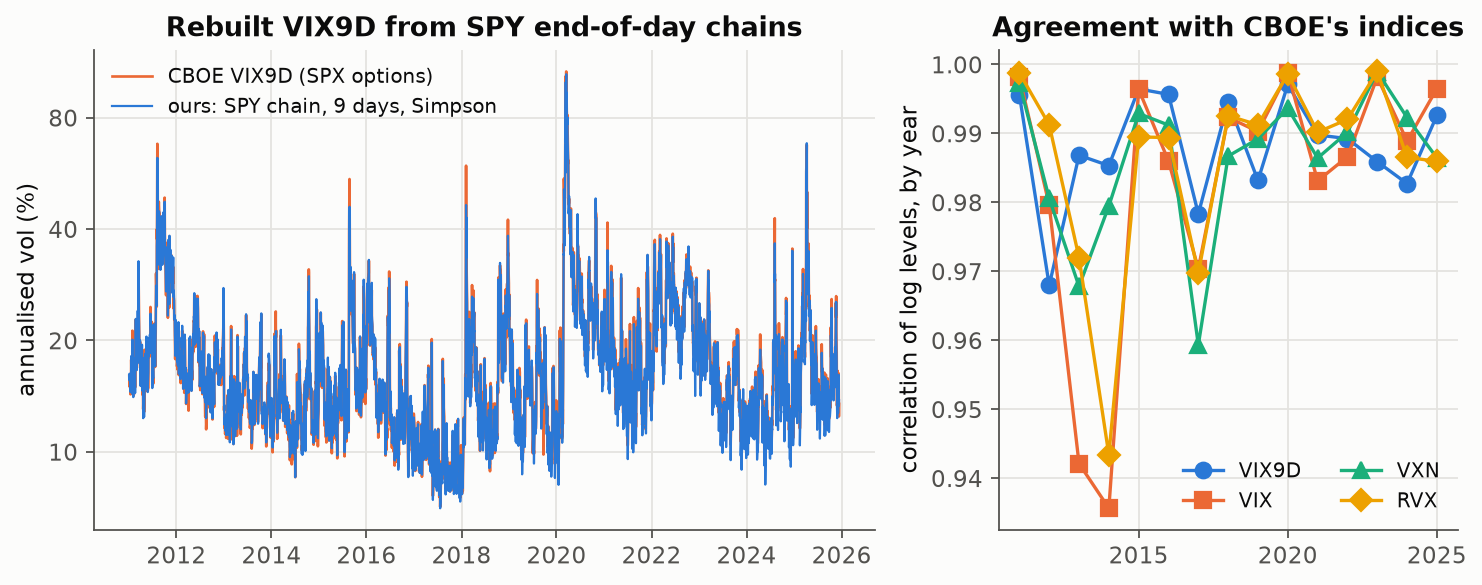

In [20]:
# Stored output of the 2011-2025 run on licensed chains, which can't be shared. Rerunning this cell shows nothing.
# To build the index from your own data, use the next cell.

The left panel shows the 9-day index rebuilt from SPY chains (blue) on top of CBOE's VIX9D (orange) from 2011 to
2025, on a log scale. The two lines are hard to tell apart, including in the spikes of 2011, 2015, 2018, 2020 and
2025. The right panel shows the correlation of log levels with each of CBOE's four indices, year by year. It is above
0.98 in most years, and the lowest values, between 0.94 and 0.97, fall in 2012 to 2014 and 2017.

In [21]:
# Yearly correlation of log levels with CBOE's indices, from the stored run (numbers only, no data).
yearly = pd.DataFrame.from_dict({
    2011: (0.996, 0.998, 0.997, 0.999),
    2012: (0.968, 0.980, 0.981, 0.991),
    2013: (0.987, 0.942, 0.968, 0.972),
    2014: (0.985, 0.936, 0.980, 0.943),
    2015: (0.997, 0.996, 0.993, 0.990),
    2016: (0.996, 0.986, 0.991, 0.989),
    2017: (0.978, 0.970, 0.959, 0.970),
    2018: (0.995, 0.992, 0.987, 0.993),
    2019: (0.983, 0.990, 0.989, 0.991),
    2020: (0.997, 0.999, 0.994, 0.999),
    2021: (0.990, 0.983, 0.986, 0.990),
    2022: (0.989, 0.987, 0.990, 0.992),
    2023: (0.986, 0.998, 0.999, 0.999),
    2024: (0.983, 0.989, 0.992, 0.987),
    2025: (0.993, 0.997, 0.986, 0.986),
}, orient="index", columns=["VIX9D", "VIX", "VXN", "RVX"]).rename_axis("year")
display(yearly.style.format("{:.3f}"))

,VIX9D,VIX,VXN,RVX
year,,,,
2011,0.996,0.998,0.997,0.999
2012,0.968,0.980,0.981,0.991
2013,0.987,0.942,0.968,0.972
2014,0.985,0.936,0.980,0.943
2015,0.997,0.996,0.993,0.990
2016,0.996,0.986,0.991,0.989
2017,0.978,0.970,0.959,0.970
2018,0.995,0.992,0.987,0.993
2019,0.983,0.990,0.989,0.991


In [22]:
# Run the build on your own chain, a parquet or csv file with columns date, expiration, strike, type, bid, ask.
# The rate file is a csv with columns date, rate (annual percent, e.g. FRED DTB3). Leave CHAIN_FILE = None to skip.
CHAIN_FILE, RATE_FILE, HORIZON = None, None, 5

if CHAIN_FILE is None:
    print("No chain supplied: skipped. Set CHAIN_FILE and RATE_FILE to build the index from your own data.")
else:
    chain = pd.read_parquet(CHAIN_FILE) if str(CHAIN_FILE).endswith(".parquet") else pd.read_csv(CHAIN_FILE)
    chain["date"], chain["expiration"] = pd.to_datetime(chain.date), pd.to_datetime(chain.expiration)
    rates = pd.read_csv(RATE_FILE, na_values=".")
    rate = pd.Series(rates.iloc[:, 1].to_numpy(float), index=pd.to_datetime(rates.iloc[:, 0])).dropna()
    try:
        import pandas_market_calendars as mcal
        sessions = mcal.get_calendar("NYSE").valid_days(chain.date.min(), chain.expiration.max()).tz_localize(None)
    except ImportError:
        sessions = pd.bdate_range(chain.date.min(), chain.expiration.max())   # holidays then count as sessions
    table = expiry_table(chain, rate, sessions)
    result = pd.concat([per_session_variance(table, HORIZON), calendar_vol(table, 9), calendar_vol(table, 30)], axis=1)
    display(result.tail())

No chain supplied: skipped. Set CHAIN_FILE and RATE_FILE to build the index from your own data.


## 9. Does horizon matching help a forecast?

The 5-session index was used as the implied-volatility input of a 5-session variance forecast (a HAR model, to be
published separately). The forecast was scored once on 2024-01-02 to 2025-12-12 (490 forecast dates) with QLIKE loss,
$L = y/\hat y - \ln(y/\hat y) - 1$ (lower is better), against the same model fed CBOE's index, with a Diebold–Mariano
test.

| ETF | CBOE input replaced | Horizon 5 sessions | p-value | Horizon 1 session |
|---|---|---:|---:|---:|
| SPY | VIX9D | −1.3% | 0.59 | −13% (p < 0.01) |
| QQQ | VXN (30 days) | −12.9% | 0.04 | −15% (p < 0.01) |
| IWM | RVX (30 days) | −23.4% | 0.015 | −35% (p < 0.01) |

- SPY shows no difference at 5 sessions. VIX9D is already short-dated, and our index is essentially VIX9D.
- QQQ and IWM gain a lot, because the only public indices are 30-day measures and a 5-day forecast needs 5-day
  information. Most of the gain is in the April 2025 sell-off.
- Beyond 10 sessions there is no winner. At 5 sessions CBOE's discretisation bias is small (0.1–0.4%), so this gain
  comes from matching the horizon, not from Simpson's rule.
- The test window was used once, under rules fixed beforehand.

## 10. Limitations and references

### Limitations
- The index measures $-2\mathbb E[\ln S_T/F]$, which differs from expected quadratic variation when the price jumps
  (Section 7.4).
- Only quoted strikes count, and on a \$0.01 tick the wings end early (Sections 7.2 and 7.3).
- Changes in strike spacing near the money bring back a second-order error (Section 3.6).
- End-of-day quotes are a noisy snapshot, and mids of wide quotes add noise, mostly in the wings.
- ETF options are American. For short-dated OTM options the early-exercise premium is tiny, so it is ignored.
- $w$ is the market's risk-neutral price of variance, typically above realised variance (the variance risk premium).
  It is a predictor of future variance, not a forecast of it.

### References
- Carr, P. and Madan, D. (1998). Towards a theory of volatility trading. In Volatility, Risk Books.
- Demeterfi, K., Derman, E., Kamal, M. and Zou, J. (1999). More than you ever wanted to know about volatility swaps.
  Goldman Sachs Quantitative Strategies.
- Britten-Jones, M. and Neuberger, A. (2000). Option prices, implied price processes, and stochastic volatility.
  Journal of Finance.
- Jiang, G. and Tian, Y. (2005). The model-free implied volatility and its information content. Review of Financial
  Studies.
- Carr, P. and Wu, L. (2009). Variance risk premiums. Review of Financial Studies.
- CBOE. VIX White Paper.
- Heston, S. and Todorov, K. Exploring the variance risk premium across assets. Working paper, SSRN 4373509.
- Heston, S., Jones, C., Khorram, M., Li, S. and Mo, H. (2023). Option momentum. Journal of Finance 78(6).
- Heston, S. (1993). A closed-form solution for options with stochastic volatility. Review of Financial Studies.
- Lewis, A. (2001). A simple option formula for general jump-diffusion and other exponential Lévy processes.
- Albrecher, H., Mayer, P., Schoutens, W. and Tistaert, J. (2007). The little Heston trap. Wilmott Magazine.
- French, K. and Roll, R. (1986). Stock return variances, the arrival of information and the reaction of traders.
  Journal of Financial Economics.
- Patton, A. (2011). Volatility forecast comparison using imperfect volatility proxies. Journal of Econometrics.